# Классификация изображений одежды Fashion MNIST

В этой работе создаётся собственная модель классификации изображений одежды. В отличие от базового примера с полносвязной нейронной сетью, здесь используется свёрточная нейронная сеть (CNN), которая учитывает пространственную структуру изображения.

Цель — обучить модель распознавать 10 категорий одежды, оценить качество на тестовой выборке и посмотреть примеры предсказаний.

## 1. Импорт библиотек и воспроизводимость результатов

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

I0000 00:00:1793196261.894538    2132 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793196286.674615    2132 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793196299.825044    2132 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0


## 2. Загрузка набора данных

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка/топ", "Брюки", "Пуловер", "Платье", "Пальто",
    "Сандалии", "Рубашка", "Кроссовки", "Сумка", "Ботильоны"
]

print("Обучающие изображения:", x_train.shape)
print("Тестовые изображения:", x_test.shape)
print("Количество классов:", len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Обучающие изображения: (60000, 28, 28)
Тестовые изображения: (10000, 28, 28)
Количество классов: 10


## 3. Просмотр примеров данных

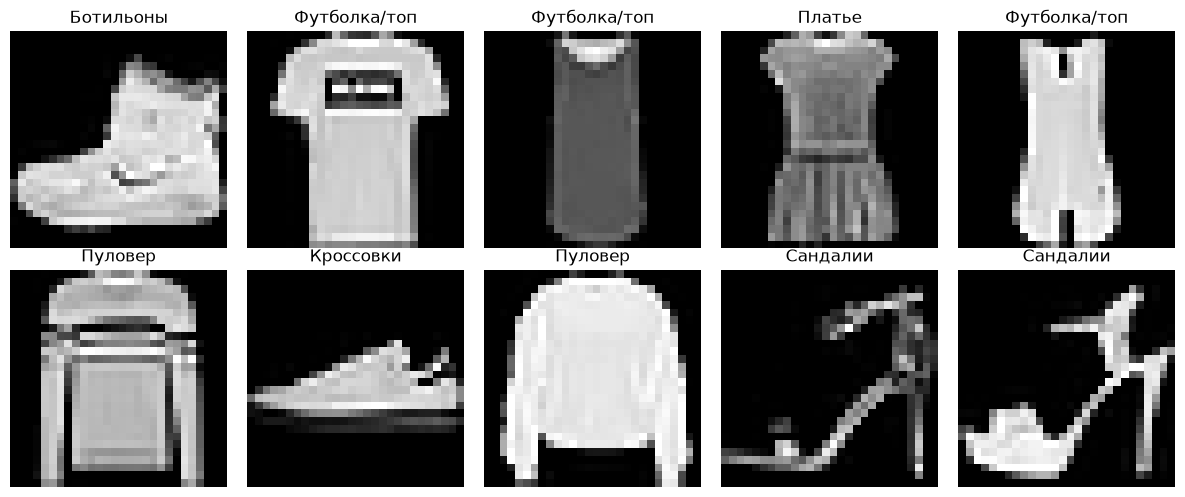

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(class_names[int(y_train[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Подготовка данных

Значения пикселей исходных изображений находятся в диапазоне от 0 до 255. Делим их на 255, чтобы привести к диапазону от 0 до 1. Для свёрточной сети добавляем последнюю размерность — один канал оттенков серого.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Форма после подготовки:", x_train.shape)

Форма после подготовки: (60000, 28, 28, 1)


## 5. Создание собственной свёрточной нейронной сети

Свёрточные слои выделяют локальные признаки изображения, например контуры и текстуры. MaxPooling уменьшает пространственный размер признаков, а Dropout помогает снизить риск переобучения.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
], name="fashion_cnn")

model.summary()

E0000 00:00:1793196318.084717    2132 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "fashion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Компиляция модели

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 7. Обучение модели

Используем 10 эпох и выделяем 20% обучающих изображений для проверки качества во время обучения. EarlyStopping прекращает обучение, если качество на валидационной выборке перестаёт улучшаться, и восстанавливает лучшие веса.

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10


W0000 00:00:1793196318.697963    2132 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 54ms/step - accuracy: 0.8168 - loss: 0.5040 - val_accuracy: 0.8802 - val_loss: 0.3297
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.8829 - loss: 0.3243 - val_accuracy: 0.8973 - val_loss: 0.2826
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.8986 - loss: 0.2786 - val_accuracy: 0.9042 - val_loss: 0.2607
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.9093 - loss: 0.2461 - val_accuracy: 0.9077 - val_loss: 0.2442
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.9195 - loss: 0.2191 - val_accuracy: 0.9102 - val_loss: 0.2402
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.9274 - loss: 0.2000 - val_accuracy: 0.9128 - val_loss: 0.2381
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 44ms/step - accuracy: 0.9337 - loss: 0.1813 - val_accuracy: 0.9157 - val_loss: 0.2337
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.9378 - loss: 0.1660 - val_accurac

## 8. Графики обучения

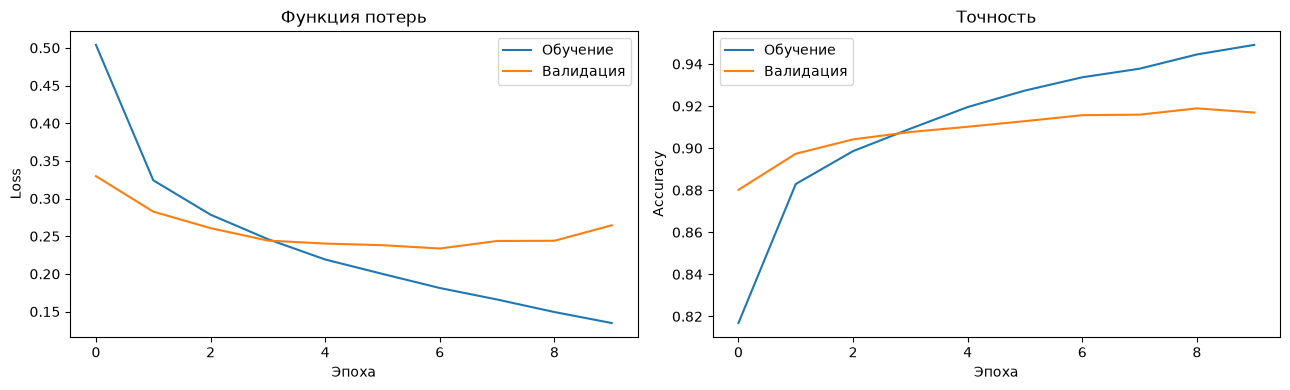

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Обучение")
axes[0].plot(history.history["val_loss"], label="Валидация")
axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Обучение")
axes[1].plot(history.history["val_accuracy"], label="Валидация")
axes[1].set_title("Точность")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Оценка на тестовой выборке

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Потери на тестовой выборке: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

Потери на тестовой выборке: 0.2518
Точность на тестовой выборке: 0.9099 (90.99%)


## 10. Примеры предсказаний

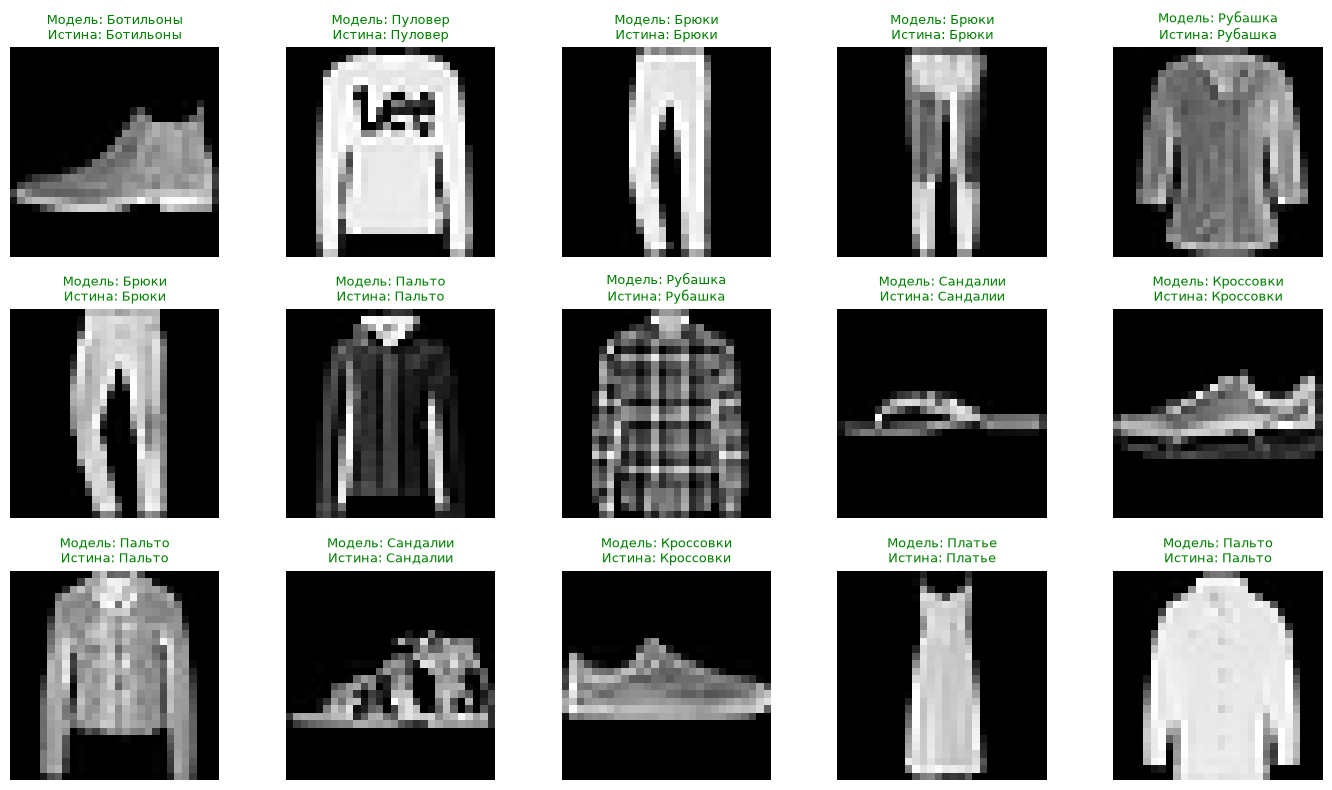

In [10]:
probabilities = model.predict(x_test[:15], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    predicted_name = class_names[int(predicted_labels[i])]
    true_name = class_names[int(y_test[i])]
    color = "green" if predicted_labels[i] == y_test[i] else "red"
    ax.set_title(f"Модель: {predicted_name}\nИстина: {true_name}", color=color, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Матрица ошибок

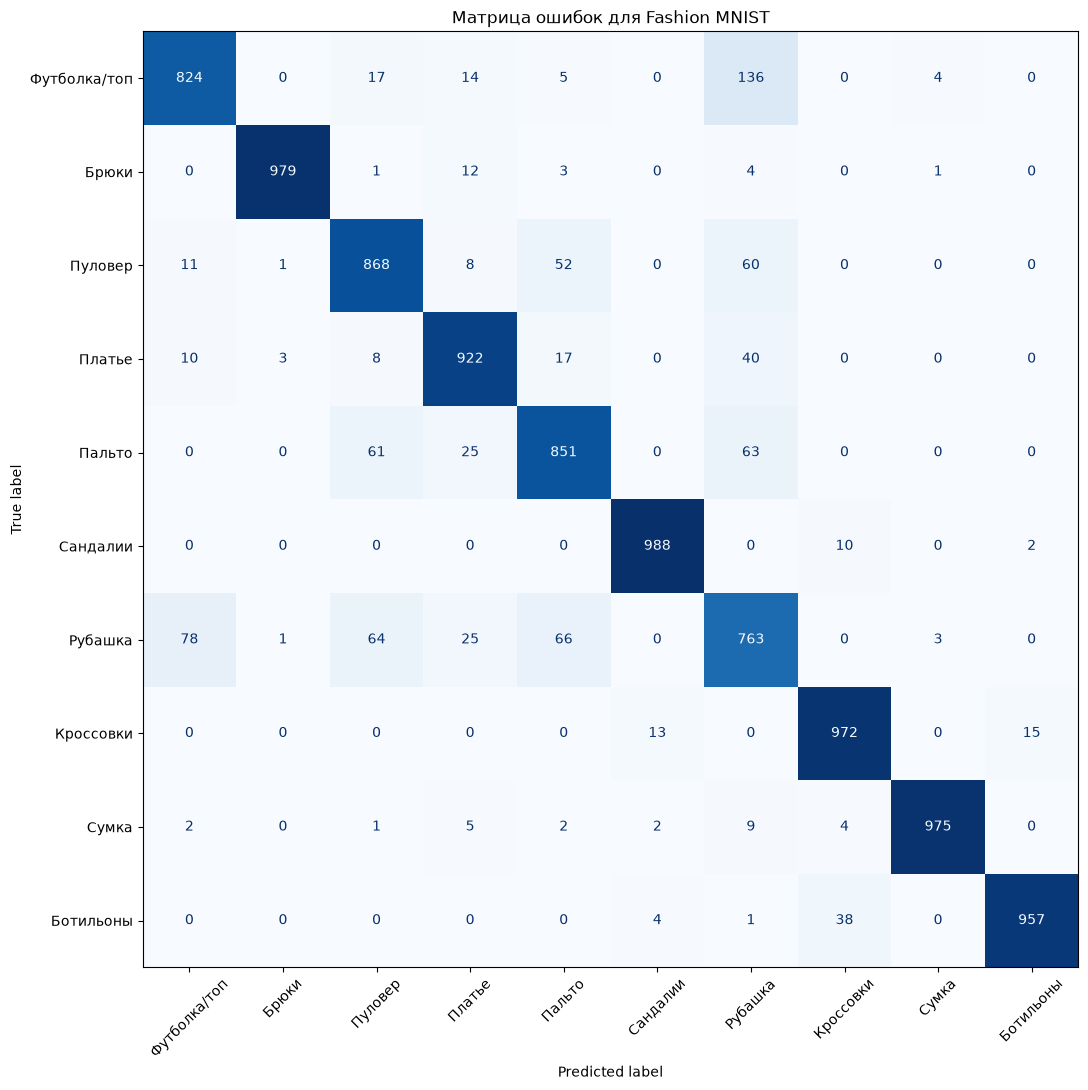

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_probabilities = model.predict(x_test, batch_size=256, verbose=0)
all_predictions = np.argmax(all_probabilities, axis=1)
cm = confusion_matrix(y_test, all_predictions)

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(11, 11))
display.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Матрица ошибок для Fashion MNIST")
plt.tight_layout()
plt.show()

## 12. Вывод

В работе была реализована свёрточная нейронная сеть для классификации изображений Fashion MNIST. Данные нормализованы, модель обучена с контролем качества на валидационной выборке, а итоговая точность проверена на отдельной тестовой выборке. Графики помогают оценить динамику обучения, примеры предсказаний показывают работу модели на отдельных изображениях, а матрица ошибок позволяет увидеть, какие классы чаще всего путаются.
